# ME 263 Applied FEA: Reduced Order Models (ROM)

Lecture of 26 Oct 2026 &nbsp;|&nbsp; Topic: how to choose the coefficients $y_i(\boldsymbol\mu)$ of a ROM

**Notes by: Vamshik M**

---

These are my **handwritten notes** from the lecture. The pages are shown in the order of the lecture, each page cut into topics, with a few short points between the images for orientation.

If you would rather read everything as text and equations, jump to the last section: **For those who purely want it in text format**.

**Contents**
1. Recap: what a ROM is
2. The toy example used throughout
3. Four strategies for choosing $y$
4. Why the $A$-norm makes sense
5. General idea with $r$ basis vectors
6. For those who purely want it in text format

## 1. Recap: what a ROM is

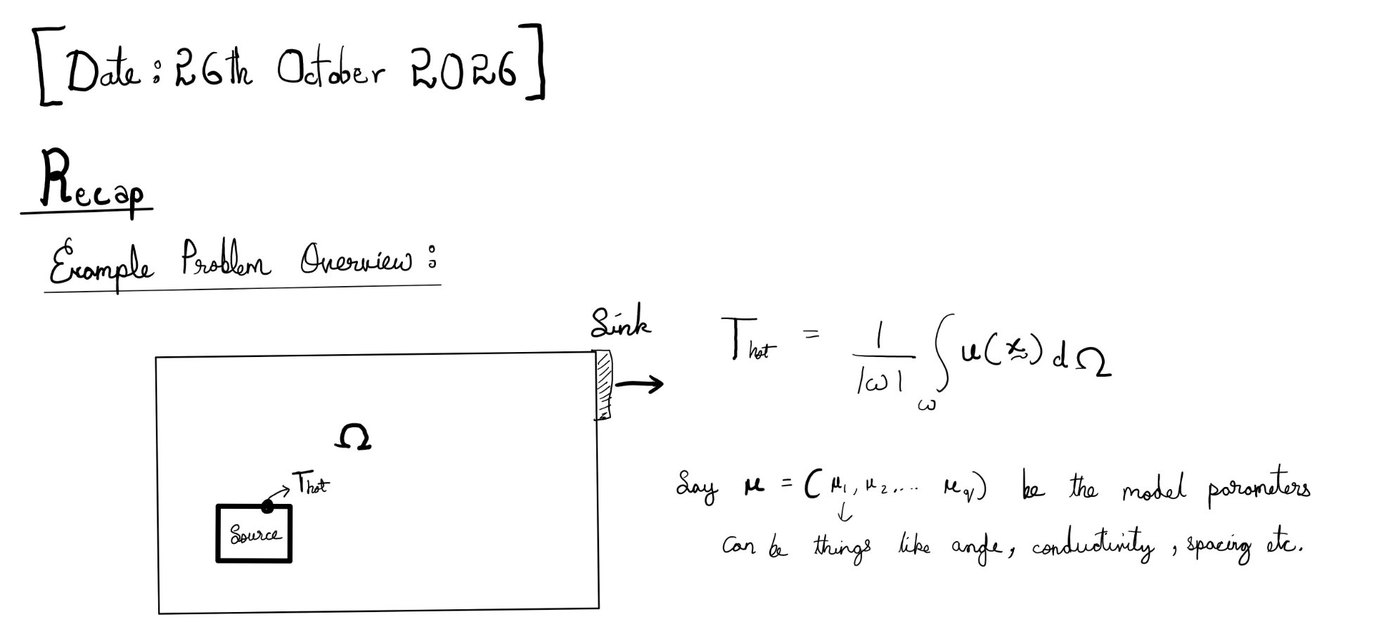

**In short**
- A domain $\Omega$ has a source and a sink (where $u=0$). The quantity of interest is the average over the source region, $T_{\text{hot}}=\frac{1}{|\omega|}\int_\omega u\,d\Omega$.
- The model parameters are $\boldsymbol\mu=(\mu_1,\dots,\mu_q)$: things like angle, conductivity, spacing.

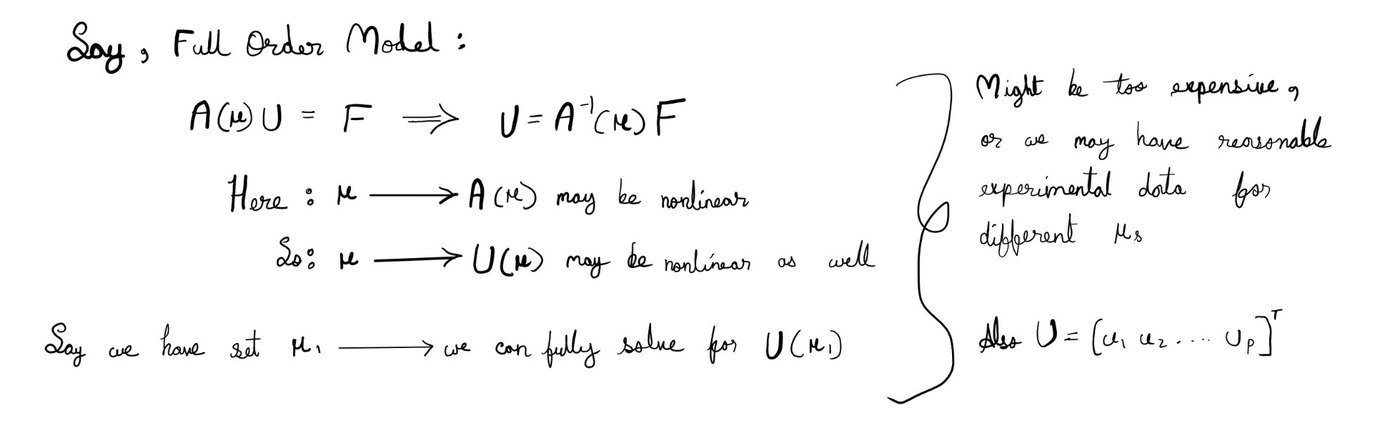

**In short**
- Full order model: $\mathbf A(\boldsymbol\mu)\mathbf U=\mathbf F$, so $\mathbf U=\mathbf A^{-1}(\boldsymbol\mu)\mathbf F$.
- $\boldsymbol\mu\mapsto\mathbf A(\boldsymbol\mu)$ may be nonlinear, so $\boldsymbol\mu\mapsto\mathbf U(\boldsymbol\mu)$ may be nonlinear too.
- One full solve per $\boldsymbol\mu$ can be too expensive, or we may only have experimental data at some $\boldsymbol\mu$'s.

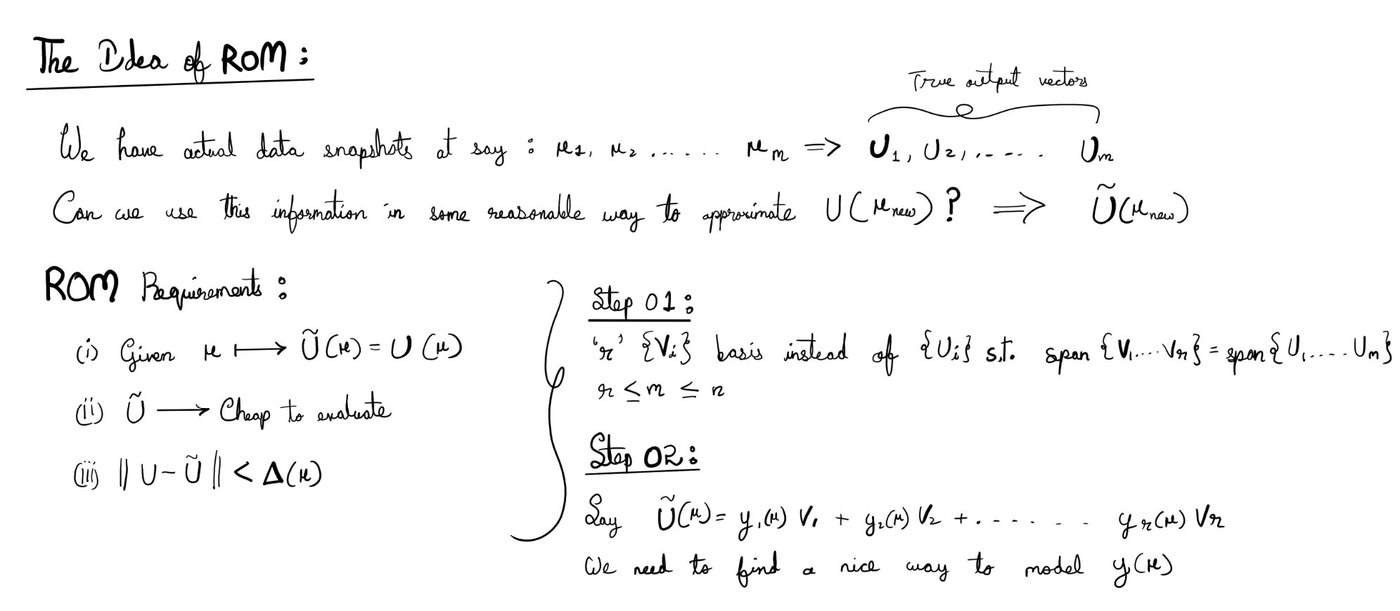

**In short**
- Use the snapshots $\mathbf U_1,\dots,\mathbf U_m$ (true outputs at $\boldsymbol\mu_1,\dots,\boldsymbol\mu_m$) to approximate $\mathbf U(\boldsymbol\mu_{\text{new}})$ by $\tilde{\mathbf U}(\boldsymbol\mu_{\text{new}})$.
- Requirements: (i) $\tilde{\mathbf U}\approx\mathbf U$, (ii) $\tilde{\mathbf U}$ is cheap, (iii) $\lVert\mathbf U-\tilde{\mathbf U}\rVert<\Delta(\boldsymbol\mu)$.
- **Step 01:** pick $r$ basis vectors $\{\mathbf V_i\}$ instead of $\{\mathbf U_i\}$ with $r\le m\le n$. How to pick them is the topic of the next lecture.
- **Step 02:** write $\tilde{\mathbf U}(\boldsymbol\mu)=\sum_i y_i(\boldsymbol\mu)\mathbf V_i$. **Today's question: how do we choose the $y_i$?**

## 2. The toy example used throughout

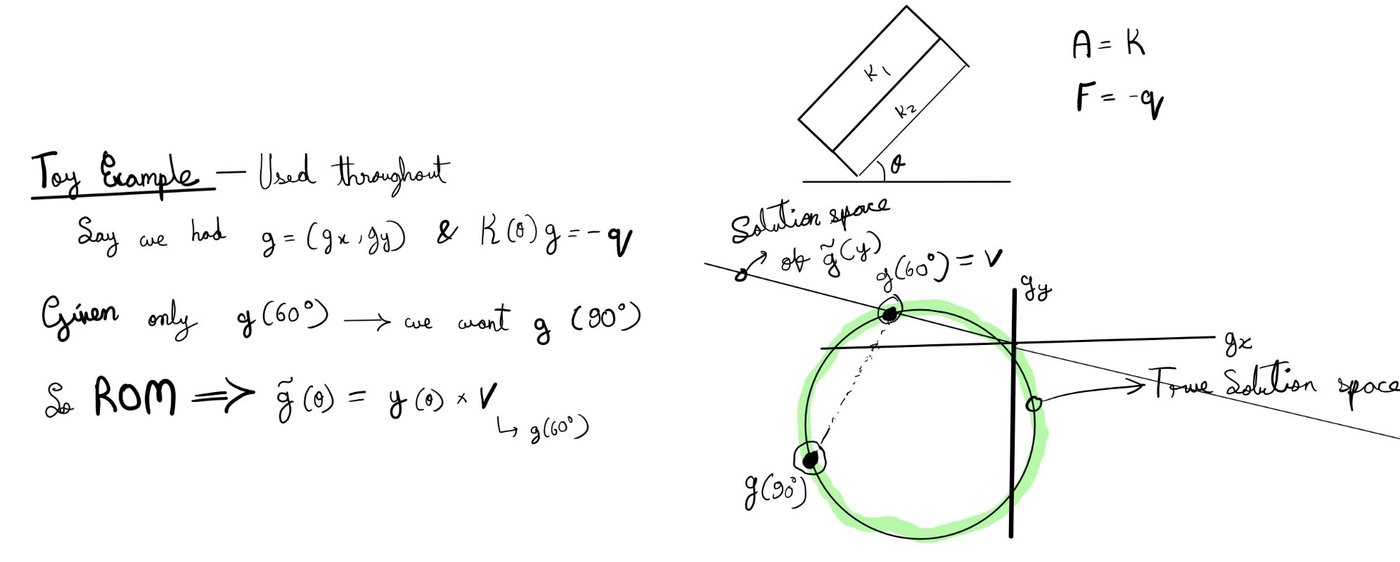

**In short**
- A layered slab (conductivities $K_1,K_2$) tilted at angle $\theta$. The unknown is $\mathbf g=(g_x,g_y)$ with $\mathbf K(\theta)\,\mathbf g=-\mathbf q$.
- This is the general system in disguise: $\mathbf A=\mathbf K$, $\mathbf F=-\mathbf q$, and $\mathbf U\leftrightarrow\mathbf g$.
- We are given only $\mathbf g(60^\circ)=\mathbf V$ and want $\mathbf g(90^\circ)$. The ROM is $\tilde{\mathbf g}(\theta)=y(\theta)\,\mathbf V$.
- In the sketch, the true solutions lie on the **circle**, while every ROM answer lies on the **line** through $\mathbf V$. The job is to pick the right point on that line.

## 3. Four strategies for choosing $y$

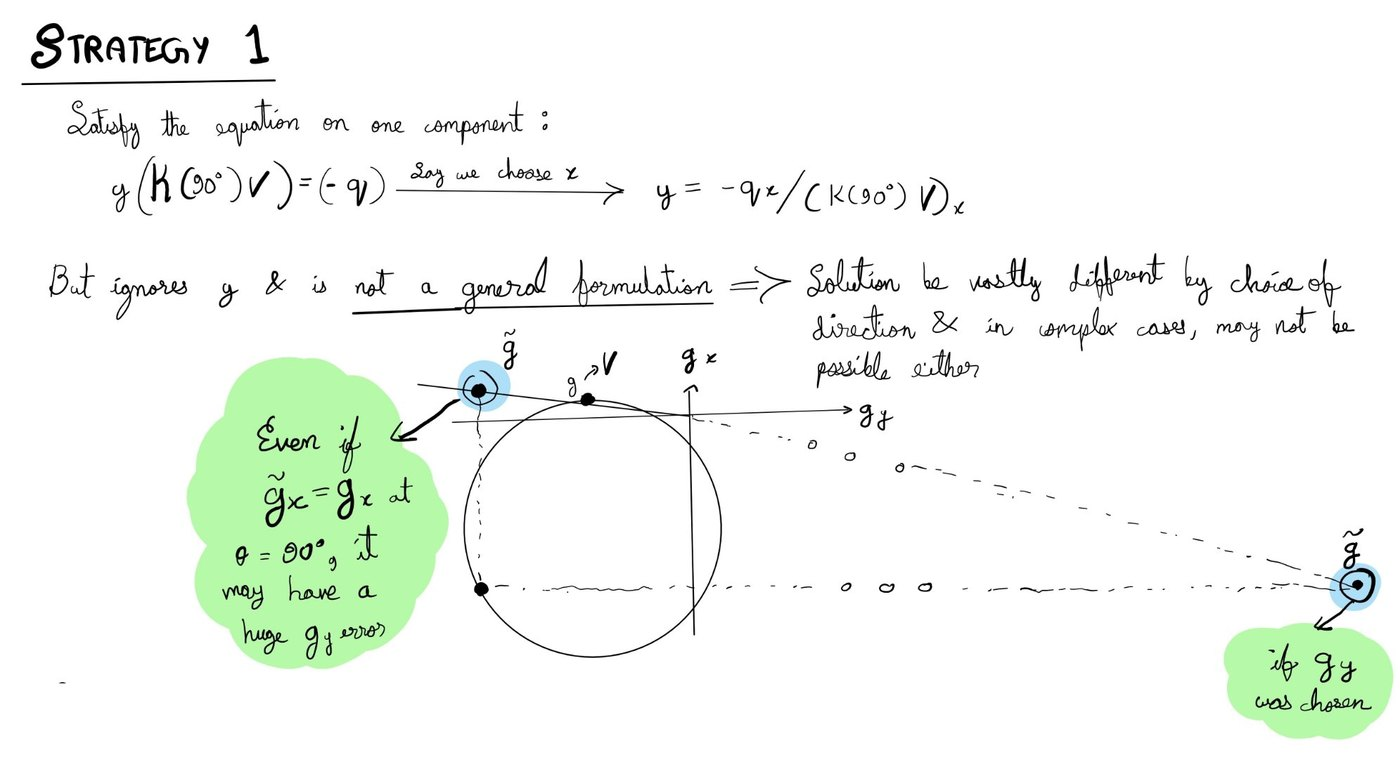

**Strategy 1, in short**
- Enforce the equation on **one component** only: $y=-q_x/(\mathbf K(90^\circ)\mathbf V)_x$.
- It ignores the other component, is not a general formulation, and the answer can change vastly with the component chosen.
- In the sketch: matching $g_x$ at $90^\circ$ can still leave a huge $g_y$ error, and choosing $g_y$ instead lands far away on the line.

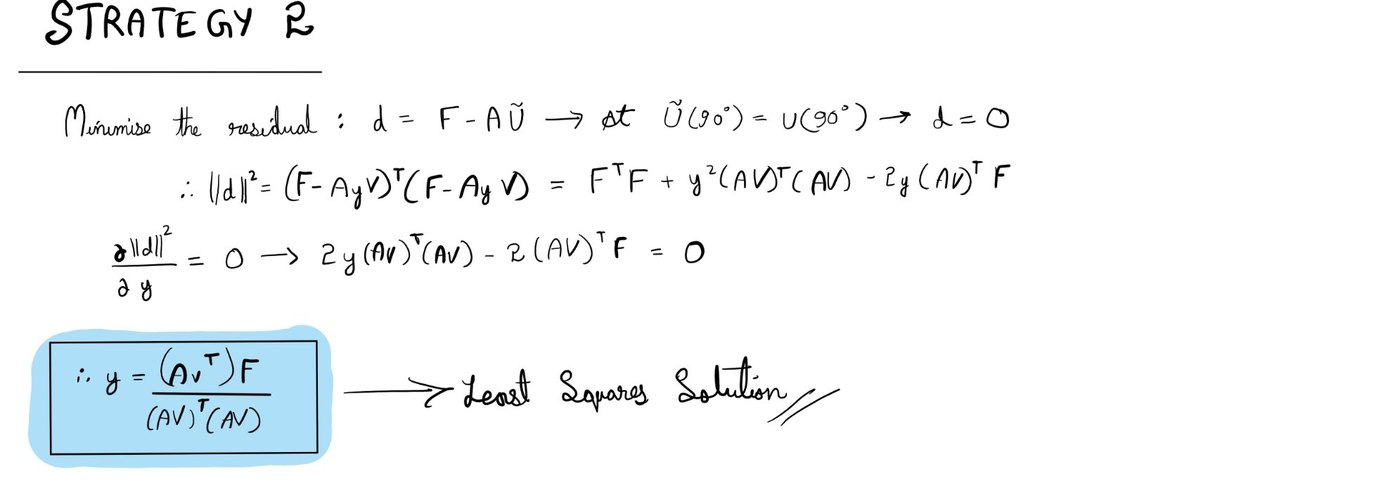

**Strategy 2, in short**
- Minimise the **residual** $\mathbf d=\mathbf F-\mathbf A\tilde{\mathbf U}$ (it is zero if $\tilde{\mathbf U}(90^\circ)=\mathbf U(90^\circ)$).
- Setting $\partial\lVert\mathbf d\rVert^2/\partial y=0$ gives $y=\dfrac{(\mathbf A\mathbf V)^{\mathsf T}\mathbf F}{(\mathbf A\mathbf V)^{\mathsf T}(\mathbf A\mathbf V)}$, the **least squares solution**.
- It uses only known quantities ($\mathbf A$, $\mathbf F$, $\mathbf V$), so it is computable.

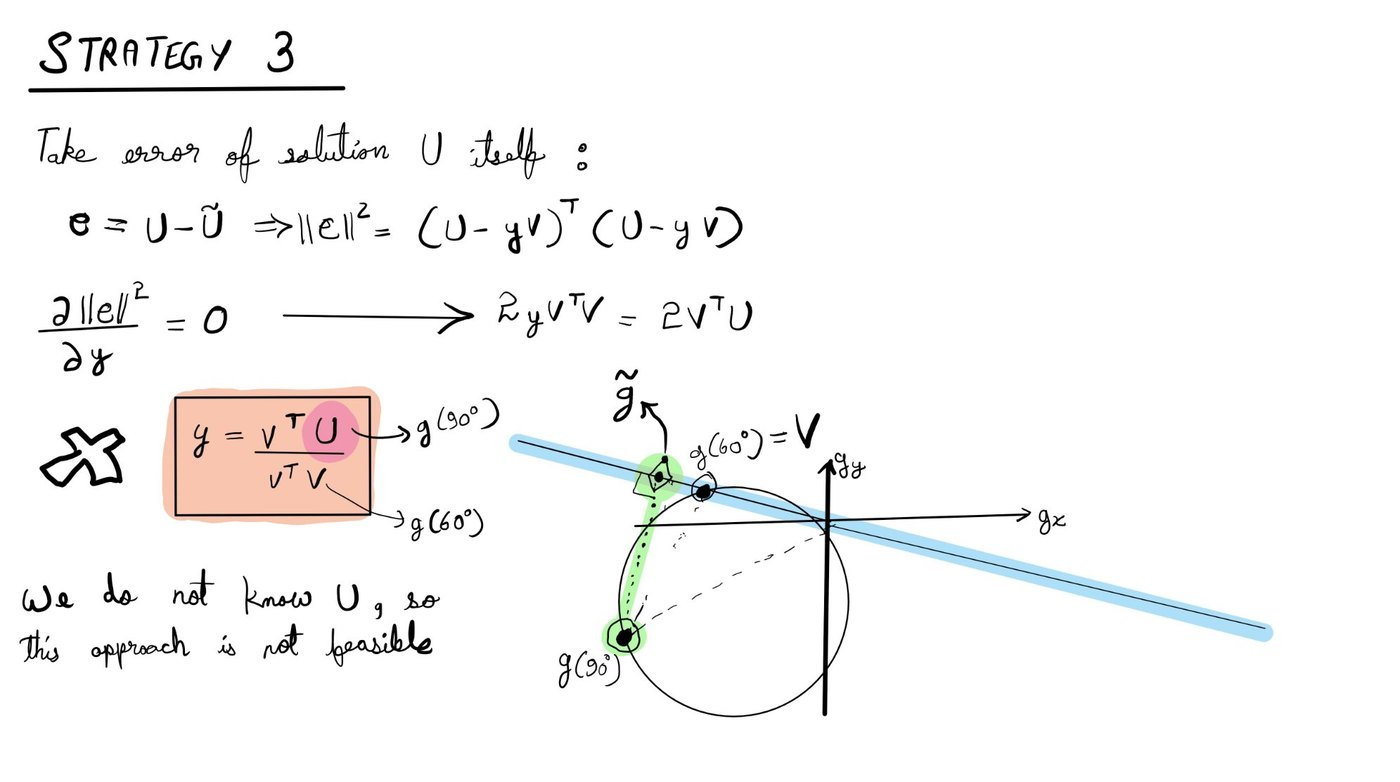

**Strategy 3, in short**
- Minimise the **error** $\mathbf e=\mathbf U-\tilde{\mathbf U}$ itself. This gives $y=\dfrac{\mathbf V^{\mathsf T}\mathbf U}{\mathbf V^{\mathsf T}\mathbf V}$: the nearest point on the line to the true solution.
- Here $\mathbf U$ is $\mathbf g(90^\circ)$ and $\mathbf V$ is $\mathbf g(60^\circ)$. But we **do not know $\mathbf U$**, so this approach is **not feasible**.

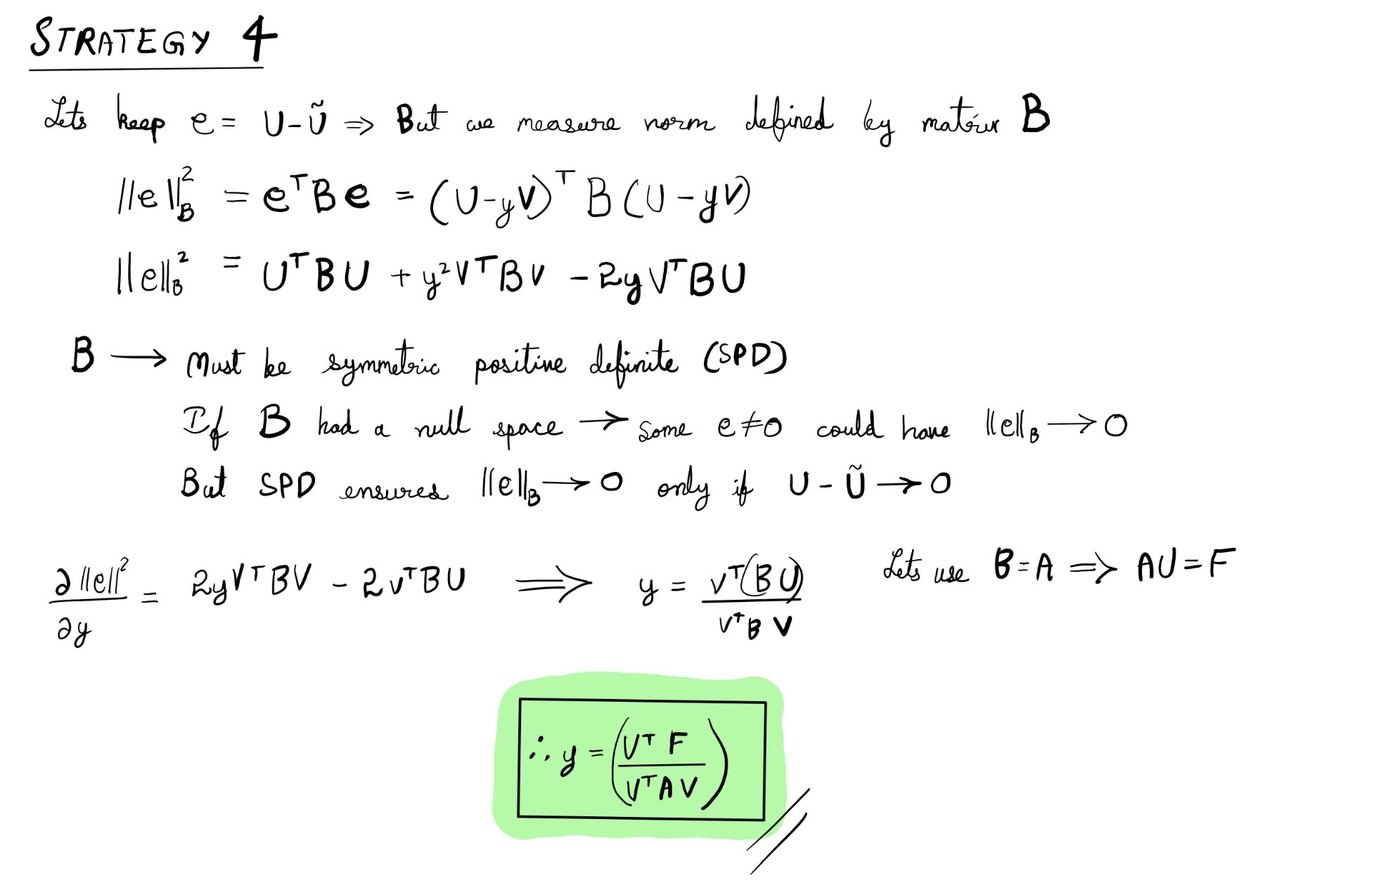

**Strategy 4, in short**
- Keep $\mathbf e=\mathbf U-\tilde{\mathbf U}$ but measure it in a norm defined by a matrix $\mathbf B$: $\lVert\mathbf e\rVert_{\mathbf B}^2=\mathbf e^{\mathsf T}\mathbf B\mathbf e$.
- $\mathbf B$ must be **symmetric positive definite**. A null space would let some $\mathbf e\ne0$ have $\lVert\mathbf e\rVert_{\mathbf B}\to0$, while SPD ensures $\lVert\mathbf e\rVert_{\mathbf B}\to0$ only if $\mathbf U-\tilde{\mathbf U}\to0$.
- The trick: choose $\mathbf B=\mathbf A$, so that $\mathbf A\mathbf U=\mathbf F$ removes the unknown $\mathbf U$.

- Setting the derivative to zero gives $y=\dfrac{\mathbf V^{\mathsf T}\mathbf B\mathbf U}{\mathbf V^{\mathsf T}\mathbf B\mathbf V}$, and with $\mathbf B=\mathbf A$ the boxed result is $y=\dfrac{\mathbf V^{\mathsf T}\mathbf F}{\mathbf V^{\mathsf T}\mathbf A\mathbf V}$.

## 4. Why the $A$-norm makes sense

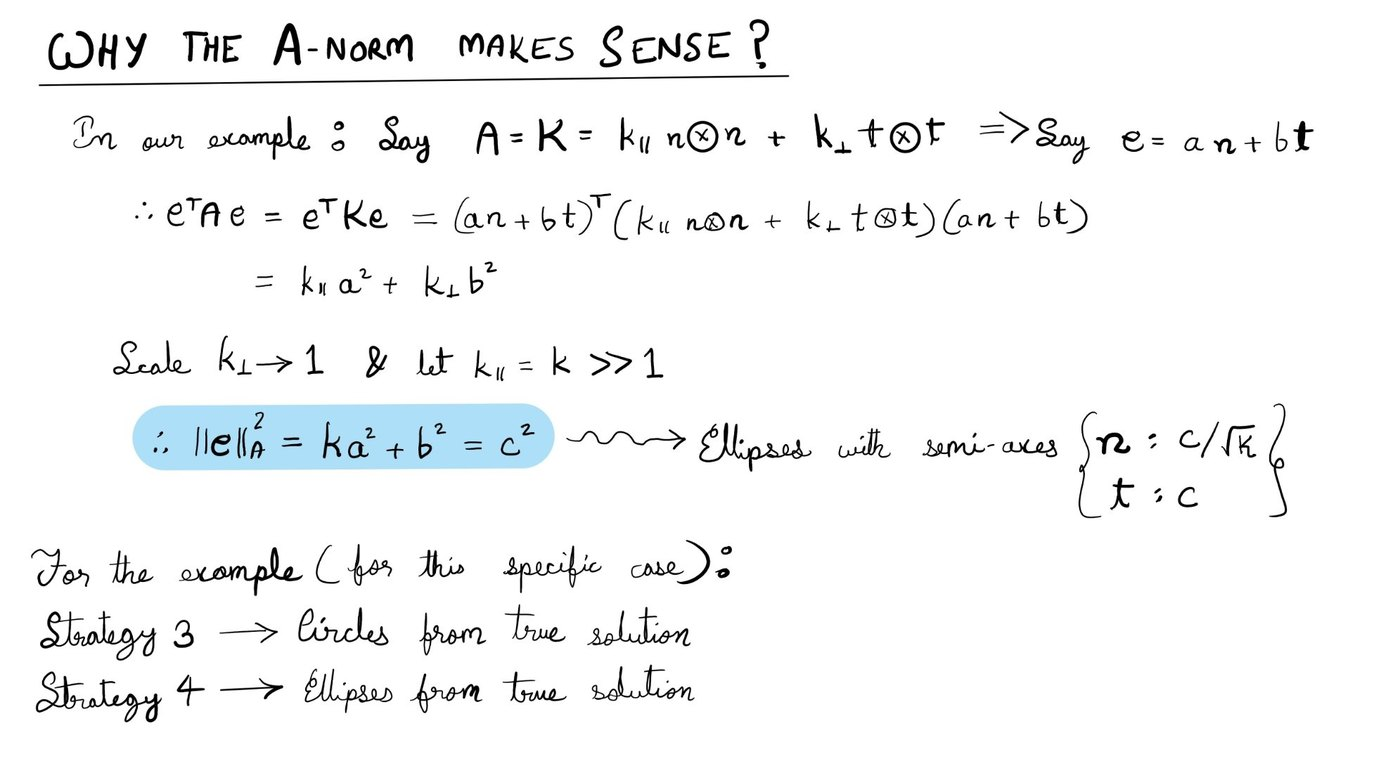

**In short**
- In our example $\mathbf A=\mathbf K=k_\parallel\,\mathbf n\otimes\mathbf n+k_\perp\,\mathbf t\otimes\mathbf t$. Write the error as $\mathbf e=a\mathbf n+b\mathbf t$.
- Then $\mathbf e^{\mathsf T}\mathbf A\mathbf e=k_\parallel a^2+k_\perp b^2$. Scaling $k_\perp\to1$ and $k_\parallel=k\gg1$ gives $\lVert\mathbf e\rVert_{\mathbf A}^2=ka^2+b^2=c^2$.
- These are **ellipses** with semi-axes $c/\sqrt k$ along $\mathbf n$ and $c$ along $\mathbf t$.
- For this case: Strategy 3 gives **circles** around the true solution, Strategy 4 gives **ellipses** around it.

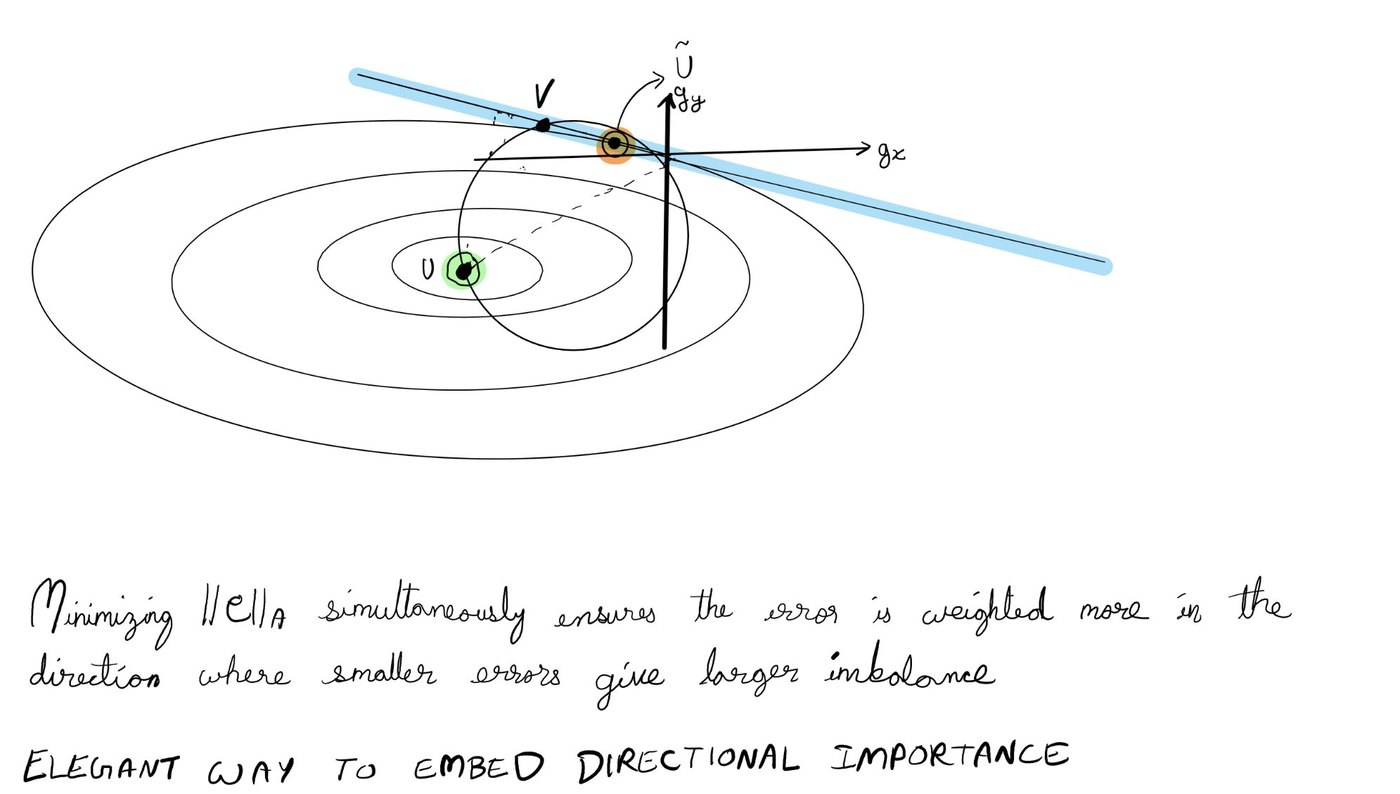

**In short**
- The sketch shows the ellipses around the true solution $\mathbf U$, the line of ROM answers (blue), and the answer $\tilde{\mathbf U}$ that Strategy 4 picks.
- The ellipses are wide along $g_x$ and thin along $g_y$, because at $\theta=90^\circ$ the fibre direction $\mathbf n$ points along $g_y$ (so $\mathbf K(90^\circ)=\mathrm{diag}(k_\perp,k_\parallel)$).
- Minimising $\lVert\mathbf e\rVert_{\mathbf A}$ weights the error more in the direction where smaller errors give a larger imbalance: an elegant way to embed directional importance.

## 5. General idea with $r$ basis vectors

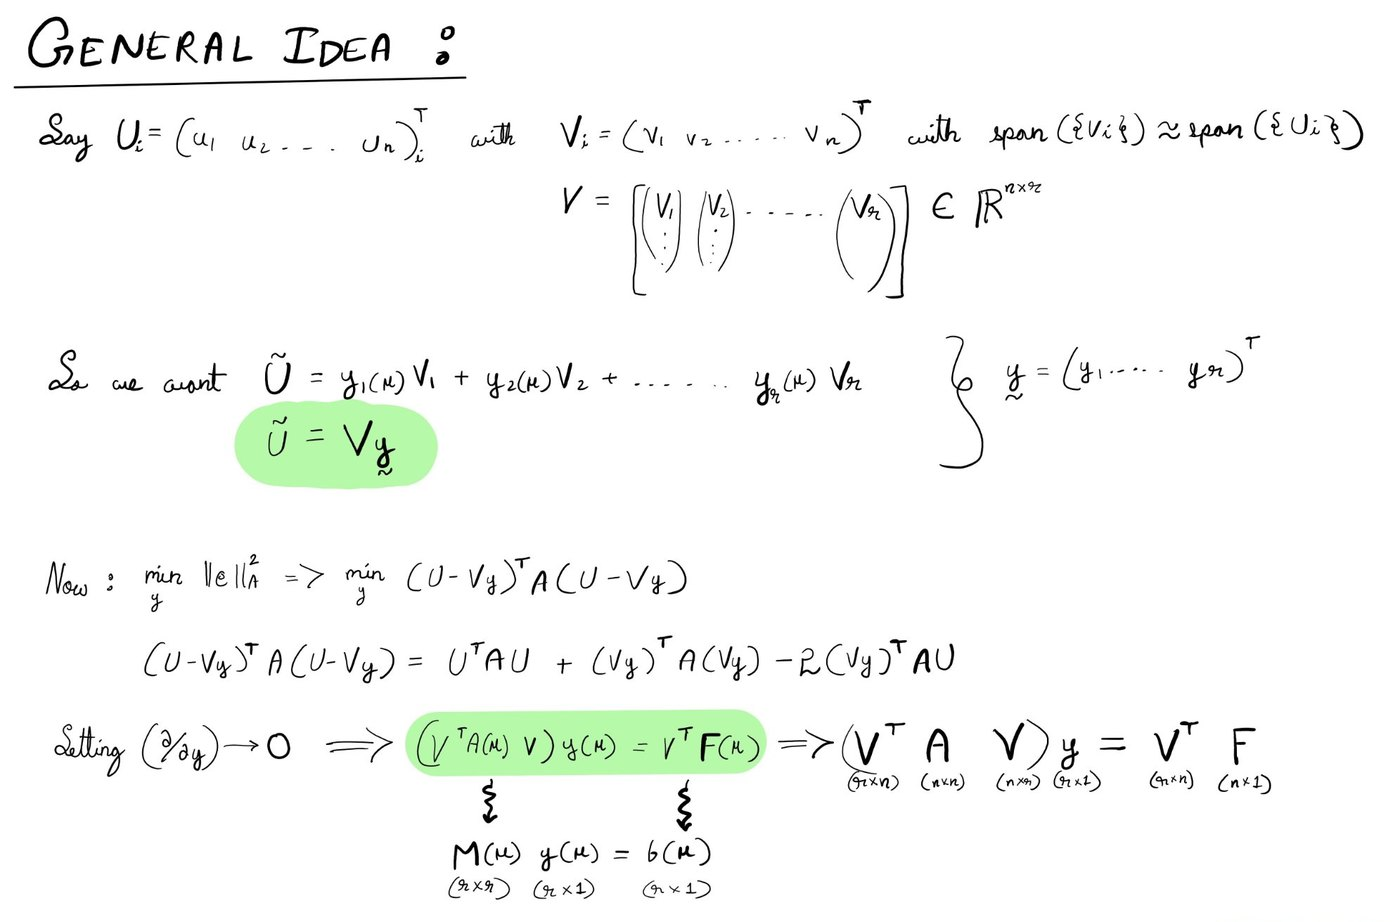

**In short**
- Stack the basis vectors into $\mathbf V=[\mathbf V_1\ \cdots\ \mathbf V_r]\in\mathbb R^{n\times r}$ and write $\tilde{\mathbf U}=\mathbf V\mathbf y$ with $\mathbf y=(y_1,\dots,y_r)^{\mathsf T}$.
- Minimise $\lVert\mathbf e\rVert_{\mathbf A}^2=(\mathbf U-\mathbf V\mathbf y)^{\mathsf T}\mathbf A(\mathbf U-\mathbf V\mathbf y)$. Setting $\partial/\partial\mathbf y\to0$ gives
$$(\mathbf V^{\mathsf T}\mathbf A(\boldsymbol\mu)\mathbf V)\,\mathbf y(\boldsymbol\mu)=\mathbf V^{\mathsf T}\mathbf F(\boldsymbol\mu)\quad\Longleftrightarrow\quad \mathbf M(\boldsymbol\mu)\,\mathbf y(\boldsymbol\mu)=\mathbf b(\boldsymbol\mu).$$
- Sizes: $\mathbf M$ is $r\times r$, $\mathbf y$ and $\mathbf b$ are $r\times1$. The full $n\times n$ solve has become an $r\times r$ solve.

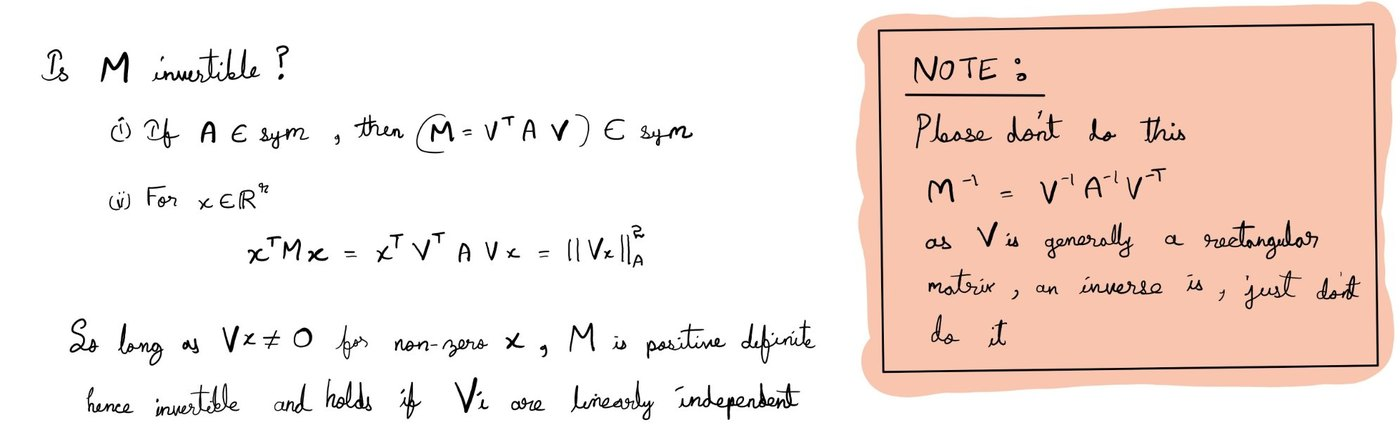

**In short**
- If $\mathbf A$ is symmetric then $\mathbf M=\mathbf V^{\mathsf T}\mathbf A\mathbf V$ is symmetric, and $\mathbf x^{\mathsf T}\mathbf M\mathbf x=\lVert\mathbf V\mathbf x\rVert_{\mathbf A}^2$.
- So as long as $\mathbf V\mathbf x\ne0$ for non-zero $\mathbf x$, $\mathbf M$ is positive definite and hence invertible. This holds if the $\mathbf V_i$ are **linearly independent**.
- **Note:** do not write $\mathbf M^{-1}=\mathbf V^{-1}\mathbf A^{-1}\mathbf V^{-\mathsf T}$. $\mathbf V$ is generally rectangular, so it has no inverse. Solve $\mathbf M\mathbf y=\mathbf b$ directly.

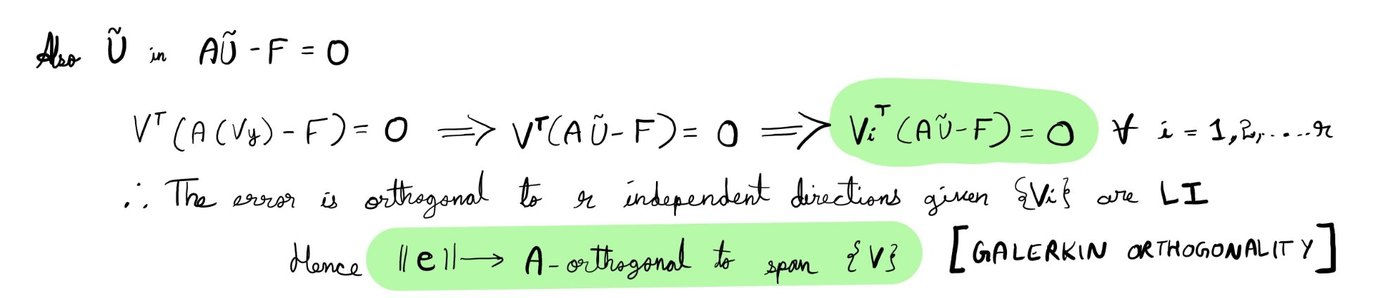

**In short**
- From the reduced equations, $\mathbf V^{\mathsf T}(\mathbf A\tilde{\mathbf U}-\mathbf F)=0$, i.e. $\mathbf V_i\cdot(\mathbf A\tilde{\mathbf U}-\mathbf F)=0$ for all $i=1,\dots,r$.
- So the **residual** is orthogonal to the $r$ independent directions (given $\{\mathbf V_i\}$ are linearly independent). Since $\mathbf A\tilde{\mathbf U}-\mathbf F=-\mathbf A\mathbf e$, the **error is $\mathbf A$-orthogonal** to $\operatorname{span}\{\mathbf V\}$: this is **Galerkin orthogonality**.

---

# For those who purely want it in text format (GPT Transcripted)
---

## 1. Recap: what a ROM is

**Example problem.** A domain $\Omega$ contains a heat source and a sink on the boundary where $u=0$. The quantity of interest is the average over the source region $\omega$:

$$T_{\text{hot}}=\frac{1}{|\omega|}\int_{\omega}u(\mathbf x)\,d\Omega .$$

Let $\boldsymbol\mu=(\mu_1,\mu_2,\dots,\mu_q)$ be the model parameters (angle, conductivity, spacing, etc.).

**Full order model.**

$$\mathbf A(\boldsymbol\mu)\,\mathbf U=\mathbf F\quad\Rightarrow\quad\mathbf U=\mathbf A^{-1}(\boldsymbol\mu)\,\mathbf F,\qquad \mathbf U=[u_1,u_2,\dots,u_n]^{\mathsf T}.$$

- $\boldsymbol\mu\mapsto\mathbf A(\boldsymbol\mu)$ may be nonlinear, so $\boldsymbol\mu\mapsto\mathbf U(\boldsymbol\mu)$ may be nonlinear as well.
- For a chosen $\boldsymbol\mu_1$ we can fully solve for $\mathbf U(\boldsymbol\mu_1)$. That might be too expensive, or we may only have reasonable experimental data for some values of $\boldsymbol\mu$.

**The idea of ROM.** We have actual data snapshots at $\boldsymbol\mu_1,\boldsymbol\mu_2,\dots,\boldsymbol\mu_m$, which give the true output vectors $\mathbf U_1,\mathbf U_2,\dots,\mathbf U_m$. Can we use this information in some reasonable way to approximate $\mathbf U(\boldsymbol\mu_{\text{new}})$ by $\tilde{\mathbf U}(\boldsymbol\mu_{\text{new}})$?

**ROM requirements**

1. Given $\boldsymbol\mu\mapsto\tilde{\mathbf U}(\boldsymbol\mu)\approx\mathbf U(\boldsymbol\mu)$.
2. $\tilde{\mathbf U}$ is cheap to evaluate.
3. $\lVert\mathbf U-\tilde{\mathbf U}\rVert<\Delta(\boldsymbol\mu)$.

**Step 01.** Use $r$ basis vectors $\{\mathbf V_i\}$ instead of $\{\mathbf U_i\}$ such that
$\operatorname{span}\{\mathbf V_1,\dots,\mathbf V_r\}\approx\operatorname{span}\{\mathbf U_1,\dots,\mathbf U_m\}$, with $r\le m\le n$. (How to pick them: next lecture.)

**Step 02.** Write $\tilde{\mathbf U}(\boldsymbol\mu)=y_1(\boldsymbol\mu)\mathbf V_1+y_2(\boldsymbol\mu)\mathbf V_2+\dots+y_r(\boldsymbol\mu)\mathbf V_r$. We need to find a nice way to model $y_i(\boldsymbol\mu)$. **This is today's topic.**

---

## 2. Toy example (used throughout)

A layered slab with conductivities $K_1$ and $K_2$, tilted at angle $\theta$. Let $\mathbf g=(g_x,g_y)$ and

$$\mathbf K(\theta)\,\mathbf g=-\mathbf q .$$

In the general notation, $\mathbf A=\mathbf K$, $\mathbf F=-\mathbf q$, and $\mathbf U\leftrightarrow\mathbf g$ (so $n=2$).

Given only $\mathbf g(60^\circ)$, we want $\mathbf g(90^\circ)$. So the ROM is

$$\tilde{\mathbf g}(\theta)=y(\theta)\,\mathbf V,\qquad \mathbf V=\mathbf g(60^\circ).$$

In the $(g_x,g_y)$ plane the true solutions $\mathbf g(\theta)$ lie on a circle, while every ROM answer $y\mathbf V$ lies on the line through $\mathbf V$. The task is to choose the right point on that line.

**First requirement:** at the snapshot angle, $\tilde{\mathbf g}(60^\circ)=y(60^\circ)\,\mathbf g(60^\circ)$, so $y(60^\circ)=1$.

---

## 3. Four strategies for choosing $y$

### Strategy 1: satisfy the equation on one component

We need $\mathbf K(90^\circ)\,y\,\mathbf V\approx-\mathbf q$. Choose, say, the $x$ component:

$$y\,(\mathbf K(90^\circ)\mathbf V)_x=-q_x\quad\Rightarrow\quad y=\frac{-q_x}{(\mathbf K(90^\circ)\mathbf V)_x}.$$

- It ignores the other component and is not a general formulation.
- The solution can be vastly different depending on the choice of direction (component).
- In complex cases it may not be possible at all (for example if $(\mathbf K\mathbf V)_x=0$).
- Even if $\tilde g_x=g_x$ at $\theta=90^\circ$, it may have a huge $g_y$ error. If $g_y$ was chosen instead, the answer lands far away on the line.

### Strategy 2: minimise the residual (least squares)

Residual: $\mathbf d=\mathbf F-\mathbf A\tilde{\mathbf U}$. At $\tilde{\mathbf U}(90^\circ)=\mathbf U(90^\circ)$ we would have $\mathbf d=0$. With $\tilde{\mathbf U}=y\mathbf V$:

$$\lVert\mathbf d\rVert^2=(\mathbf F-\mathbf A y\mathbf V)^{\mathsf T}(\mathbf F-\mathbf A y\mathbf V)=\mathbf F^{\mathsf T}\mathbf F+y^2(\mathbf A\mathbf V)^{\mathsf T}(\mathbf A\mathbf V)-2y\,(\mathbf A\mathbf V)^{\mathsf T}\mathbf F .$$

Setting $\dfrac{\partial\lVert\mathbf d\rVert^2}{\partial y}=0$:

$$2y\,(\mathbf A\mathbf V)^{\mathsf T}(\mathbf A\mathbf V)-2\,(\mathbf A\mathbf V)^{\mathsf T}\mathbf F=0
\quad\Rightarrow\quad
\boxed{\,y=\frac{(\mathbf A\mathbf V)^{\mathsf T}\mathbf F}{(\mathbf A\mathbf V)^{\mathsf T}(\mathbf A\mathbf V)}\,}\qquad\text{(least squares solution)}$$

### Strategy 3: minimise the error directly (not feasible)

Take the error of the solution $\mathbf U$ itself: $\mathbf e=\mathbf U-\tilde{\mathbf U}$, so

$$\lVert\mathbf e\rVert^2=(\mathbf U-y\mathbf V)^{\mathsf T}(\mathbf U-y\mathbf V),\qquad
\frac{\partial\lVert\mathbf e\rVert^2}{\partial y}=0\;\Rightarrow\;2y\,\mathbf V^{\mathsf T}\mathbf V=2\,\mathbf V^{\mathsf T}\mathbf U
\;\Rightarrow\;y=\frac{\mathbf V^{\mathsf T}\mathbf U}{\mathbf V^{\mathsf T}\mathbf V}.$$

Here $\mathbf U$ is $\mathbf g(90^\circ)$ and $\mathbf V$ is $\mathbf g(60^\circ)$. Geometrically this is the point on the line nearest to the true solution. But **we do not know $\mathbf U$, so this approach is not feasible.**

### Strategy 4: measure the error in a weighted norm

Keep $\mathbf e=\mathbf U-\tilde{\mathbf U}$ but measure it in the norm defined by a matrix $\mathbf B$:

$$\lVert\mathbf e\rVert_{\mathbf B}^2=\mathbf e^{\mathsf T}\mathbf B\,\mathbf e=(\mathbf U-y\mathbf V)^{\mathsf T}\mathbf B(\mathbf U-y\mathbf V)=\mathbf U^{\mathsf T}\mathbf B\mathbf U+y^2\,\mathbf V^{\mathsf T}\mathbf B\mathbf V-2y\,\mathbf V^{\mathsf T}\mathbf B\mathbf U .$$

- $\mathbf B$ must be **symmetric positive definite** (SPD).
- If $\mathbf B$ had a null space, some $\mathbf e\ne0$ could have $\lVert\mathbf e\rVert_{\mathbf B}\to0$.
- SPD ensures $\lVert\mathbf e\rVert_{\mathbf B}\to0$ only if $\mathbf U-\tilde{\mathbf U}\to0$.

Setting the derivative to zero, $\dfrac{\partial\lVert\mathbf e\rVert_{\mathbf B}^2}{\partial y}=2y\,\mathbf V^{\mathsf T}\mathbf B\mathbf V-2\,\mathbf V^{\mathsf T}\mathbf B\mathbf U=0$, so

$$y=\frac{\mathbf V^{\mathsf T}\mathbf B\,\mathbf U}{\mathbf V^{\mathsf T}\mathbf B\,\mathbf V}\qquad\text{(still contains }\mathbf U\text{).}$$

Now use $\mathbf B=\mathbf A$, so that $\mathbf A\mathbf U=\mathbf F$:

$$\boxed{\,y=\frac{\mathbf V^{\mathsf T}\mathbf F}{\mathbf V^{\mathsf T}\mathbf A\,\mathbf V}\,}$$

This uses only known quantities.

---

## 4. Why the $A$-norm makes sense

In our example $\mathbf A=\mathbf K=k_\parallel\,\mathbf n\otimes\mathbf n+k_\perp\,\mathbf t\otimes\mathbf t$. Say $\mathbf e=a\,\mathbf n+b\,\mathbf t$. Then

$$\mathbf e^{\mathsf T}\mathbf A\,\mathbf e=\mathbf e^{\mathsf T}\mathbf K\mathbf e=(a\mathbf n+b\mathbf t)^{\mathsf T}\bigl(k_\parallel\,\mathbf n\otimes\mathbf n+k_\perp\,\mathbf t\otimes\mathbf t\bigr)(a\mathbf n+b\mathbf t)=k_\parallel a^2+k_\perp b^2 .$$

Scale $k_\perp\to1$ and let $k_\parallel=k\gg1$. Then

$$\lVert\mathbf e\rVert_{\mathbf A}^2=k\,a^2+b^2=c^2,$$

which describes **ellipses** with semi-axes $c/\sqrt k$ along $\mathbf n$ and $c$ along $\mathbf t$.

For this specific case:
- **Strategy 3** gives **circles** around the true solution.
- **Strategy 4** gives **ellipses** around the true solution.

At $\theta=90^\circ$ the fibre direction $\mathbf n$ points along $g_y$, so $\mathbf K(90^\circ)=\mathrm{diag}(k_\perp,k_\parallel)$ and, in the $(g_x,g_y)$ plane, the ellipses are wide along $g_x$ and thin along $g_y$.

Minimising $\lVert\mathbf e\rVert_{\mathbf A}$ simultaneously ensures the error is weighted more in the direction where smaller errors give a larger imbalance. It is an **elegant way to embed directional importance**.

---

## 5. General idea with $r$ basis vectors

Let $\mathbf U_i=(u_1,u_2,\dots,u_n)^{\mathsf T}$ and $\mathbf V_i=(v_1,v_2,\dots,v_n)^{\mathsf T}$ with $\operatorname{span}\{\mathbf V_i\}\approx\operatorname{span}\{\mathbf U_i\}$. Stack the basis vectors:

$$\mathbf V=\bigl[\,\mathbf V_1\ \ \mathbf V_2\ \ \cdots\ \ \mathbf V_r\,\bigr]\in\mathbb R^{n\times r}.$$

We want

$$\tilde{\mathbf U}=y_1(\boldsymbol\mu)\mathbf V_1+y_2(\boldsymbol\mu)\mathbf V_2+\dots+y_r(\boldsymbol\mu)\mathbf V_r=\mathbf V\mathbf y,\qquad \mathbf y=(y_1,\dots,y_r)^{\mathsf T}.$$

Now minimise the error in the $\mathbf A$-norm:

$$\min_{\mathbf y}\lVert\mathbf e\rVert_{\mathbf A}^2\;\Rightarrow\;\min_{\mathbf y}\,(\mathbf U-\mathbf V\mathbf y)^{\mathsf T}\mathbf A(\mathbf U-\mathbf V\mathbf y),$$

$$(\mathbf U-\mathbf V\mathbf y)^{\mathsf T}\mathbf A(\mathbf U-\mathbf V\mathbf y)=\mathbf U^{\mathsf T}\mathbf A\mathbf U+(\mathbf V\mathbf y)^{\mathsf T}\mathbf A(\mathbf V\mathbf y)-2(\mathbf V\mathbf y)^{\mathsf T}\mathbf A\mathbf U .$$

The first term has no $\mathbf y$ dependence, and $\mathbf A\mathbf U=\mathbf F$ makes the last term computable. Setting $\partial/\partial\mathbf y\to0$:

$$\boxed{\,(\mathbf V^{\mathsf T}\mathbf A(\boldsymbol\mu)\,\mathbf V)\,\mathbf y(\boldsymbol\mu)=\mathbf V^{\mathsf T}\mathbf F(\boldsymbol\mu)\,}\quad\Longleftrightarrow\quad\mathbf M(\boldsymbol\mu)\,\mathbf y(\boldsymbol\mu)=\mathbf b(\boldsymbol\mu).$$

With sizes: $(\underbrace{\mathbf V^{\mathsf T}}_{r\times n}\,\underbrace{\mathbf A}_{n\times n}\,\underbrace{\mathbf V}_{n\times r})\,\underbrace{\mathbf y}_{r\times1}=\underbrace{\mathbf V^{\mathsf T}}_{r\times n}\,\underbrace{\mathbf F}_{n\times1}$, so $\mathbf M$ is $r\times r$ and $\mathbf b$ is $r\times1$.

### Is $\mathbf M$ invertible?

1. If $\mathbf A$ is symmetric, then $\mathbf M=\mathbf V^{\mathsf T}\mathbf A\mathbf V$ is symmetric.
2. For $\mathbf x\in\mathbb R^r$: $\ \mathbf x^{\mathsf T}\mathbf M\mathbf x=\mathbf x^{\mathsf T}\mathbf V^{\mathsf T}\mathbf A\mathbf V\mathbf x=\lVert\mathbf V\mathbf x\rVert_{\mathbf A}^2$.

So as long as $\mathbf V\mathbf x\ne0$ for non-zero $\mathbf x$, $\mathbf M$ is positive definite and hence invertible. This holds if the $\mathbf V_i$ are **linearly independent**.

> **Note:** do not write $\mathbf M^{-1}=\mathbf V^{-1}\mathbf A^{-1}\mathbf V^{-\mathsf T}$. $\mathbf V$ is generally a rectangular matrix, so it has no inverse. Solve $\mathbf M\mathbf y=\mathbf b$ directly.

### How well does $\tilde{\mathbf U}$ satisfy $\mathbf A\tilde{\mathbf U}-\mathbf F=0$?

$$\mathbf V^{\mathsf T}\bigl(\mathbf A(\mathbf V\mathbf y)-\mathbf F\bigr)=0\;\Rightarrow\;\mathbf V^{\mathsf T}(\mathbf A\tilde{\mathbf U}-\mathbf F)=0\;\Rightarrow\;\mathbf V_i\cdot(\mathbf A\tilde{\mathbf U}-\mathbf F)=0\quad\forall\,i=1,2,\dots,r .$$

So the residual is orthogonal to $r$ independent directions, given that $\{\mathbf V_i\}$ are linearly independent. Since $\mathbf A\tilde{\mathbf U}-\mathbf F=-\mathbf A\mathbf e$, the error $\mathbf e$ is **$\mathbf A$-orthogonal** to $\operatorname{span}\{\mathbf V\}$. This is **Galerkin orthogonality**.

---